# U.S. Video Game Sales by Console: Mean vs. Median

**Jai Sivaya & Liam Patel** · STAT 207 (Data Science Exploration), University of Illinois Urbana-Champaign · Spring 2026
**Tools:** Python (pandas, Matplotlib)
Both authors worked on all parts of the project.

**Question:** How do typical U.S. sales per game differ across five consoles (Xbox 360, PlayStation 3, Nintendo Wii, Nintendo DS, Sony PSP)?
**Takeaway:** Sales are heavily right-skewed, so the "best" console depends on the statistic. The **Wii leads on mean** sales per game (0.69M), but the **PS3 leads on median** (0.27M); a few blockbusters inflate the Wii's average.

<hr>

## 1. Introduction

The video game industry includes many different gaming platforms, and sales performance can vary depending on the console on which a game is released. For this project, we chose to explore a dataset containing video games and their United States sales across five consoles: X360, Nintendo DS, PlayStation 3, Sony PSP, and Nintendo Wii. We selected this dataset because video games are a widely recognized form of entertainment, and we are both heavily interested in them as well. Analyzing sales data provides an interesting opportunity to understand how different platforms perform in the market. 

Our Research Question is: **In this dataset, how do typical U.S. sales per game differ across video game consoles?**

Understanding the answer to this research question can be useful for several reasons. For example, game developers or publishers may want to understand which platforms tend to have stronger average sales when deciding where to release their games or partner with for special editions. Similarly, analysts studying trends in the gaming industry may be interested in identifying which consoles tend to perform better in terms of average game sales. By examining the differences in average U.S. sales across consoles, this analysis provides insight into how platform choice may relate to sales outcomes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Dataset Discussion

The dataset used in this analysis contains information about video games and their sales performance in the United States. The unit of observation in this dataset is a single video game entry. The dataset includes details such as the console on which the game was released and the amount of sales in the United States measured in millions of copies sold.

The primary variables used in this analysis are Console and US Sales (millions). The Console variable identifies the gaming platform on which a game was released and is considered a categorical variable. In this dataset, there are five console categories: X360, Nintendo DS, PlayStation 3, Sony PSP, and Nintendo Wii. The US Sales (millions) variable measures the number of copies sold in the United States and is a quantitative variable.

Each row in the dataset represents one video game and includes its associated console and sales information. This structure makes it possible to group the data by console and calculate summary statistics, such as the average sales for games released on each platform. These variables were selected because they directly relate to the research question and allow for a clear comparison of sales performance across consoles.

One limitation of this dataset is that it only includes sales from the United States. Because the analysis does not account for sales in other regions, the results may not represent the overall global performance of video games across consoles. A console that performs well in the U.S. market may not necessarily have the same level of success in other parts of the world.

In [2]:
df = pd.read_csv("video_games.csv", encoding="unicode-escape")
df.shape

(1770, 166)

In [3]:
df[["Console", "Title", "US Sales (millions)", "YearReleased"]].head(6)

,Console,Title,US Sales (millions),YearReleased
0,Nintendo DS,Super Mario 64 DS,4.69,2004
1,Sony PSP,Lumines: Puzzle Fusion,0.56,2004
2,Nintendo DS,WarioWare Touched!,0.54,2004
3,Sony PSP,Hot Shots Golf: Open Tee,0.49,2004
4,Nintendo DS,Spider-Man 2,0.45,2004
5,Nintendo DS,The Urbz: Sims in the City,0.41,2004


In [4]:
df.columns

Index(['Console', 'Title', 'US Sales (millions)', 'Block4', 'Block2', 'Block1',
       'Block0.5', 'YearReleased', '2004', '2005',
       ...
       'Tricks', 'Volleyball', 'Wakeboarding', 'Wrestling', 'FirstPerson',
       'Platform', 'Isometric', 'SideScrolling', 'TopDown', 'ThirdPerson'],
      dtype='str', length=166)

## 3. Dataset Cleaning

In [5]:
df.isna().sum()

Console                0
Title                  0
US Sales (millions)    0
Block4                 0
Block2                 0
                      ..
Platform               0
Isometric              0
SideScrolling          0
TopDown                0
ThirdPerson            0
Length: 166, dtype: int64

In [6]:
df = df.dropna(subset=["Console", "US Sales (millions)"])
df.shape

(1770, 166)

In [7]:
df["US Sales (millions)"].describe()

count    1770.000000
mean        0.479785
std         1.064915
min         0.010000
25%         0.090000
50%         0.190000
75%         0.450000
max        14.660000
Name: US Sales (millions), dtype: float64

There were no missing values detected in either Console or US Sales (millions), so no rows were removed. We inspected the distribution of US Sales (millions) and observed a strong right-skew, with most games selling under 1 million units and a few extreme outliers reaching over 14 million. We did not remove these high values because they likely represent legitimate blockbuster titles.

## 4. Summarizing Data

To investigate the research question, summary statistics were calculated for each console, including the count, mean, median, and standard deviation of U.S. sales. The results show that the number of games differs across consoles, with the X360 having the largest number of games in the dataset (437) and the Nintendo Wii having the fewest (296).

In [8]:
Consoles_count = df["Console"].value_counts()
Consoles_count

Console
X360             437
Nintendo DS      418
PlayStation 3    312
Sony PSP         307
Nintendo Wii     296
Name: count, dtype: int64

In [9]:
df.groupby("Console")["US Sales (millions)"].agg(count="count", mean="mean", median="median", std="std")

,count,mean,median,std
Console,,,,
Nintendo DS,418,0.447943,0.12,1.121021
Nintendo Wii,296,0.691115,0.26,1.775619
PlayStation 3,312,0.457564,0.27,0.588260
Sony PSP,307,0.240326,0.13,0.339833
X360,437,0.551190,0.24,0.927919


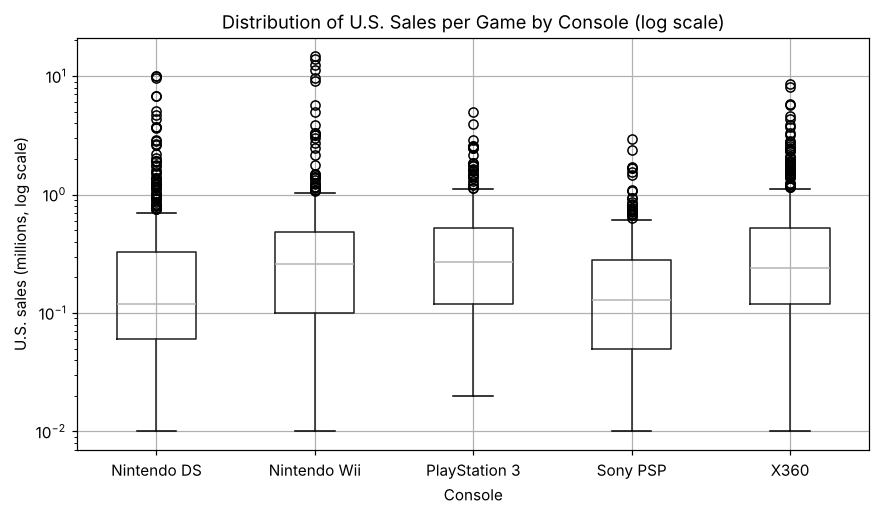

In [10]:
# Log scale: sales span 0.01M to 14.7M, so a linear axis squashes most games near zero
ax = df.boxplot(column="US Sales (millions)", by="Console", figsize=(9, 5))
plt.suptitle("")
ax.set_yscale("log")
ax.set_title("Distribution of U.S. Sales per Game by Console (log scale)")
ax.set_xlabel("Console")
ax.set_ylabel("U.S. sales (millions, log scale)")
plt.show()

The boxplots show that the distribution of U.S. sales is right-skewed across all consoles, with a number of high-value outliers representing very successful games. Because these outliers can inflate the mean, the median provides a more reliable measure of the average game sales for each console. If the mean is used to compare average sales across consoles, video game sales may be influenced by a small number of extremely successful titles. These blockbuster games can increase the mean sales for a console and make the typical performance appear higher than it actually is.

In [11]:
avg_sales = df.groupby("Console")["US Sales (millions)"].median()
avg_sales

Console
Nintendo DS      0.12
Nintendo Wii     0.26
PlayStation 3    0.27
Sony PSP         0.13
X360             0.24
Name: US Sales (millions), dtype: float64

The average U.S. sales per console were calculated through the use of grouping by console. The results have a large disparity in average sales from each console. Some of the consoles will average more than other consoles in sales per game, while others will average fewer than other consoles in sales per game. These numbers indicate that there are factors such as overall popularity of the gaming console as a platform, the game library available for the console, or the overall consumer preference that have an effect on the overall performance of the sales within any console. Sorting the averages allows for a means of direct comparison to determine which console has the highest average sales per console in the U.S.

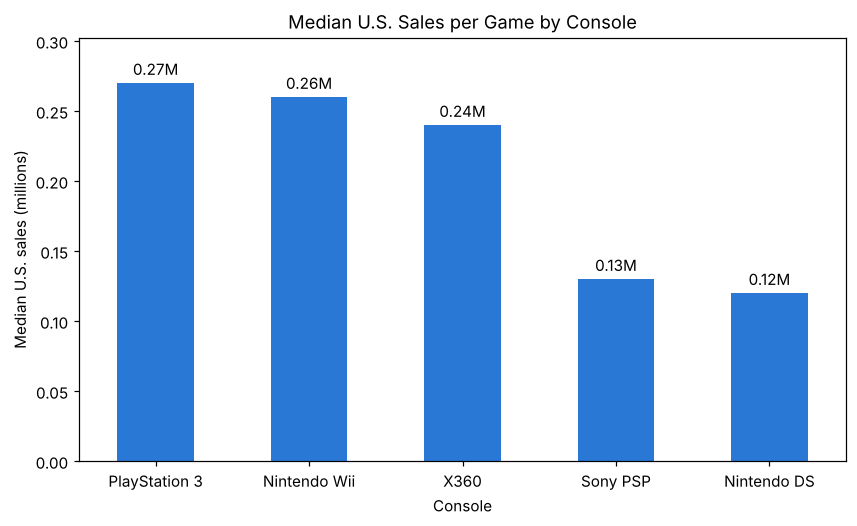

In [12]:
ax = avg_sales.sort_values(ascending=False).plot.bar(
    figsize=(9, 5), color="#2a78d6", rot=0,
    title="Median U.S. Sales per Game by Console",
    ylabel="Median U.S. sales (millions)")
ax.bar_label(ax.containers[0], fmt="%.2fM", padding=3)
ax.margins(y=0.12)
plt.show()

A bar chart of the median U.S. sales was created to visually compare the typical sales performance across consoles. The visualization shows that the PlayStation 3 and Nintendo Wii tend to have higher typical sales per game, while the Nintendo DS has the lowest typical sales among the consoles in the dataset. This visual representation helps highlight differences in sales performance across platforms.

When comparing the mean U.S. sales, the Nintendo Wii has the highest average sales at approximately 0.69 million copies per game, followed by the X360 at about 0.55 million. The PlayStation 3 and Nintendo DS have similar mean sales, around 0.46 million and 0.45 million, respectively. The Sony PSP has the lowest mean U.S. sales at approximately 0.24 million copies per game.

However, the median sales provide a clearer picture of typical game performance because video game sales can be influenced by extremely successful titles. The PlayStation 3 has the highest median sales at 0.27 million, followed closely by the Nintendo Wii at 0.26 million. The X360 has a median of 0.24 million, while the Sony PSP and Nintendo DS have lower medians of approximately 0.13 million and 0.12 million, respectively. The difference between the mean and median values, particularly for the Nintendo Wii and Nintendo DS, suggests that some games have unusually high sales that increase the average.



## 5. Conclusion

The goal of this analysis was to answer the research question: how does average United States sales differ across video game consoles in this dataset? The results show that sales performance varies across the five consoles included in the study. When comparing mean sales, the Nintendo Wii has the highest average U.S. sales per game at approximately 0.69 million copies, while the Sony PSP has the lowest average sales at about 0.24 million copies per game. However, when examining median sales, which better represent typical game performance in the presence of extremely high-selling games, the PlayStation 3 has the highest median sales at approximately 0.27 million copies per game, followed closely by the Nintendo Wii.

These findings suggest that some consoles may appear to perform better based on average sales because of a small number of blockbuster games that significantly increase the mean. The difference between the mean and median values for several consoles indicates that video game sales are somewhat skewed and influenced by high-selling titles.

There are several limitations to this analysis. The dataset only includes U.S. sales, so the results may not represent global sales patterns. Additionally, the dataset includes only five consoles, which limits the ability to generalize the findings to the broader video game industry. Other factors that could influence sales, such as game genre, release year, marketing, or franchise popularity, were not included in the analysis.

Despite these limitations, this analysis provides useful insight into how sales performance differs across consoles within the dataset. These results could be helpful for understanding general trends in video game sales and how platform differences may relate to typical game performance.